<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg" align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.891 · Aprendizaje automático · PEC1</p>
<p style="margin: 0; text-align:right;">2026-1 · Máster universitario en Ciencia de datos (Data science)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>
<br>

**PEC 1: Preparación del entorno de trabajo y de los datos**

El objetivo principal de esta primera PEC es que os familiaricéis con el entorno de trabajo que vais a utilizar en el resto de actividades de la asignatura. Dicho entorno estará formado por un conjunto de dependencias a los módulos de Python necesarios para poder ejecutar de forma correcta el código que resuelve vuestra PEC. Estas dependencias las gestionaremos gracias a la ayuda de Anaconda, que, entre otras cosas, nos provee de un gestor de entornos virtuales para Python.

Otra de las herramientas fundamentales del que será vuestro nuevo entorno de trabajo será Jupyter, que os permitirá trabajar con Notebooks (ficheros \*.ipynb), como el presente enunciado, y donde podréis ejecutar vuestro código celda a celda, mostrando los resultados intermedios que necesitéis para comprender correctamente qué es lo que estáis haciendo en cada momento.

En esta primera PEC, otro de los aspectos imprescindibles que vamos a cubrir, tal y como adelanta su título, es el de la preparación de los datos. En esta PEC aprenderemos a cargar distintos conjuntos de datos o _datasets_, los combinaremos y nos ayudaremos de herramientas de visualización para comprender mejor cómo se distribuye el dato, con el objetivo de entender cómo podemos sacarle partido. Además, nos habituaremos a trabajar con conjuntos de entrenamiento y test para confirmar si las conclusiones que sacamos sobre una parte de las muestras se pueden generalizar y extrapolar al resto.

En resumen, en esta actividad veremos cómo aplicar diferentes técnicas para la carga y preparación de datos siguiendo los pasos listados a continuación:
1. Preparación del entorno de trabajo (1 punto)<br>
2. Carga y comprensión de los distintos conjuntos de datos (1.5 puntos)<br>
3. Análisis de los datos (3 puntos)<br>
   3.1. Análisis estadístico básico<br>
   3.2. Análisis exploratorio de los datos<br>
4. Preprocesado de los datos (2.5 punto)<br>
5. Reducción de la dimensionalidad (2 puntos)<br>

**Importante:** cada uno de los ejercicios puede suponer varios minutos de ejecución, por lo que la entrega debe hacerse en formato notebook y en formato html, donde se vea el código, los resultados y comentarios de cada ejercicio. Se puede exportar el notebook a html desde el menú File $\to$ Download as $\to$ HTML.

**Importante:** existe un tipo de celda especial para albergar texto. Este tipo de celda os será muy útil para responder a las diferentes preguntas teóricas planteadas a lo largo de cada PEC. Para cambiar el tipo de celda a este tipo, elegid en el menú: Cell $\to$ Cell Type $\to$ Markdown.

**Importante:** la solución planteada no debe utilizar métodos, funciones o parámetros declarados "deprecated" en futuras versiones.

**Importante:** es conveniente que utilicéis una semilla con un valor fijo (en este Notebook se os propone la variable _seed_ inicializada a 100) en todos aquellos métodos o funciones que contengan alguna componente aleatoria para aseguraros de que obtendréis siempre el mismo resultado en las distintas ejecuciones de vuestro código.

**Importante:** no olvidéis poner vuestro nombre y apellidos en la siguiente celda.

<div style="background-color: #572e2e; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>AVISO:</strong> tened cuidado, más podría ser menos. Si os excedéis en las respuestas, podríais tener penalización en la nota. Sed concisos, sintetizad lo que queréis remarcar e id al grano por favor.
</div>

<div class="alert alert-block alert-info">
<strong>Nombre y apellidos:</strong>
</div>

Adrián Moreno García

# 1. Preparación del entorno de trabajo (1 punto)

Para la realización de la actividad necesitaremos instalar e importar una serie de módulos. El entorno especificado en el fichero *environment_uoc_20261pec1.yml* incluye sólo un subconjunto de estos módulos, por lo que será necesario que instaléis vosotros el resto de módulos que necesitaréis durante el resto de la PEC.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> el fichero de entorno que os facilitamos está incompleto, por lo que debéis completarlo para que los módulos necesarios durante el resto del Notebook estén especificados en él. Si tenéis claro qué módulos necesitáis, podéis modificar el fichero de entorno antes de importarlo. En caso contrario, podéis importar el fichero sin modificarlo e ir instalando las librerías que necesitéis después, pero procurad tener siempre actualizado el fichero de entorno, ya que es el entregable que esperamos recibir de este apartado.
<br>
<br>
<strong>Importante:</strong> es necesario que junto al Notebook en formato ipynb y HTML adjuntéis el fichero de entorno correctamente actualizado.
</div>

La gestión de dependencias en los proyectos es muy importante. Si queremos replicar su funcionamiento en otras máquinas o en el futuro, debemos tener bien especificados los módulos necesarios y sus correspondientes versiones. Es por ese motivo que es crucial aprender a gestionarlas bien.

La siguiente celda importa los módulos necesarios para el resto de la PEC.

In [133]:
import numpy as np
import pandas as pd

import folium
from branca.element import Element

from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
seed = 100

%matplotlib inline

# 2. Carga y comprensión de los distintos conjuntos de datos (1.5 puntos)

<strong>Importante:</strong> Para la realización de la PEC deberéis utilizar únicamente los conjuntos de datos que se encuentran junto al enunciado (*bcn_virtual_sensor.parquet* y *bcn_monitoring_network_inventory.csv*). Estos datasets se facilitan ya procesados debido a que la carga de procesamiento de datos es elevada para el propósito de esta PEC. El resto de enlaces son referencias adicionales por si se quiere explorar fuera del ámbito de la PEC los datos en crudo que fueron utilizados. 

En esta PEC vamos a imaginar que el Ayuntamiento de Barcelona nos ha contratado para un nuevo proyecto que busca optimizar el presupuesto del departamento de medio ambiente, evaluando si la red de sensores de tráfico junto con el resto de mediciones de calidad del aire (como partículas u ozono) pueden actuar como sustituto (proxy) de los costosos analizadores químicos de NO<sub>2</sub>. El objetivo del proyecto es evaluar la viabilidad técnica y económica de prescindir de los costosos analizadores físicos de dióxido de nitrógeno (NO<sub>2</sub>) en Barcelona mediante el desarrollo conceptual de un sensor virtual.

Para ello el Ayutamiento nos ha dado acceso a dos fuentes de datos:

- Medición de la calidad del aire: Contiene mediciones de [calidad](https://opendata-ajuntament.barcelona.cat/data/es/dataset/qualitat-aire-detall-bcn) del aire de la ciudad de Barcelona y los metadatos de las [estaciones](https://opendata-ajuntament.barcelona.cat/data/es/dataset/qualitat-aire-estacions-bcn) de monitorización. 

- Tráfico urbano: Dispone de información relativa a la congestión del [tráfico](https://opendata-ajuntament.barcelona.cat/data/es/dataset/trams) urbano y los metadatos asociados a cada [tramo](https://opendata-ajuntament.barcelona.cat/data/dataset/transit-relacio-trams) de la vía pública.

Las mediciones de calidad del aire se registran con frecuencia horaria en las 7 estaciones de monitorización operativas en la ciudad, mientras que la fluidez del tráfico se monitoriza con una frecuencia superior (sub-horaria) en más de 360 tramos de la red viaria. Dado que para poder llevar a cabo el proyecto deberíamos trabajar con un conjunto de datos en el que cada muestra (fila de la tabla) recoja las mediciones de la calidad del aire y la fluidez del tráfico urbano para una ubicación concreta, es necesario alinear ambas fuentes espacio-temporalmente y construir un conjunto de datos consolidado ("sensor virtual") donde cada muestra combine niveles de contaminantes y fluidez del tráfico para una misma coordenada y ventana temporal:

- Concatenación histórica: Se integran los ficheros mensuales de ambas fuentes para consolidar un histórico de tres años y medio de datos continuos.

- Estandarización y agregación temporal: Se procesan y agregan los datos para contar con registros horarios sincronizados(formato fecha-hora).

- Control de calidad e integridad: Se debe asegurar la calidad del dato, por lo que se eliminan duplicados por clave primaria (estación/tramo y fecha), se gestionan valores nulos e imputaciones, y se valida la coherencia física de los rangos de medición.

- Alineación espacial: Dado que las coordenadas de las estaciones de aire y los tramos viarios no coinciden, se toman como anclaje espacial las 7 estaciones de monitorización para asociarles el estado local del tráfico urbano.


Para ello, en esta PEC definimos un radio de influencia de 1.250 metros alrededor de cada estación para capturar sus tramos próximos. A continuación, asignamos una ponderación inversamente proporcional a la distancia, otorgando mayor peso a las calles contiguas a la estación de monitorización y menor peso a las más alejadas. A nivel horario, se calcula un único índice de congestión local para cada estación mediante la media ponderada de los tramos activos en su entorno. Finalmente, se cruzan las series temporales de contaminantes con este índice de tráfico agregado, construyendo el conjunto de datos del «sensor virtual», cuyo propósito es servir de base para la estimación del NO<sub>2</sub> en función del tráfico y de las variables ambientales complementarias.


## 2.1. Visualización de tramos y estaciones

<strong>Importante:</strong> Para poder ejercutar la segunda celda es necesario haber descargado previamente el fichero *bcn_monitoring_network_inventory.csv* que está disponible junto al enunciado de la PEC. 

Las dos siguientes celdas contienen el código necesario para representar en un mapa de la ciudad de Barcelona los puntos de los tramos en los que analizamos el tráfico y las 7 estaciones de monitorización de la calidad del aire. Por lo que <strong> no deberíais realizar ninguna modificación</strong> para visualizar el mapa. 

La única variable que se puede modificar es la que se encuentra en la primera celda, 'BUFFER_RADIUS_METERS', la cual define el radio de influencia de las estaciones y nos permite ver cuantos tramos de congestión de tráfico abarca. 

Al ejecutar las dos siguientes celdas podréis ver el mapa de la ciudad de Barcelona con todos los tramos y estaciones de las teníamos datos.

In [134]:
#BUFFER_RADIUS_METERS = 1800 #PRUEBA
BUFFER_RADIUS_METERS = 1250

In [135]:
inventory_df = pd.read_csv('data/bcn_monitoring_network_inventory.csv')
centroid_lat = float(inventory_df['latitude'].mean())
centroid_lon = float(inventory_df['longitude'].mean())

bcn_map = folium.Map(
    location=[centroid_lat, centroid_lon],
    zoom_start=12,
    tiles='OpenStreetMap',
    control_scale=True,
)

buffer_layer = folium.FeatureGroup(
    name=f'Influence Buffer ({BUFFER_RADIUS_METERS:,} m)'
)

traffic_layer = folium.FeatureGroup(name='Traffic Sections (~365)')
air_quality_layer = folium.FeatureGroup(name='Air Quality Stations (7)')

traffic_df = inventory_df[inventory_df['point_type'] == 'traffic_section']
for _, row in traffic_df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3.5,
        color='#023e8a',
        weight=1.0,
        fill=True,
        fill_color='#0077b6',
        fill_opacity=0.85,
        tooltip=f"<b>Traffic Section:</b> {row['name']} (ID: {row['id']})",
    ).add_to(traffic_layer)


air_quality_df = inventory_df[
    inventory_df['point_type'] == 'air_quality_station'
]
for _, row in air_quality_df.iterrows():
    folium.Circle(
        location=[row['latitude'], row['longitude']],
        radius=BUFFER_RADIUS_METERS,
        color='#d90429',
        weight=1.5,
        fill=True,
        fill_color='#ef233c',
        fill_opacity=0.12,
        dash_array='5, 5',
        tooltip=f"Buffer {BUFFER_RADIUS_METERS} m: {row['name']}",
    ).add_to(buffer_layer)

    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=8.0,
        color='#ffffff',
        weight=2.5,
        fill=True,
        fill_color='#d90429',
        fill_opacity=1.0,
        tooltip=f"<b>Air Quality Station:</b> {row['name']} (ID: {row['id']})",
    ).add_to(air_quality_layer)

buffer_layer.add_to(bcn_map)
traffic_layer.add_to(bcn_map)
air_quality_layer.add_to(bcn_map)
folium.LayerControl(collapsed=False).add_to(bcn_map)
bcn_map

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Pregunta:</strong> Cómo se ha detallado en las celdas ateriores, a cada estación de medición de calidad de aire se le han asignado los tramos en los que se puede medir la congestión del tráfico que se encuentran a una distancia máxima de 1250 metros, ¿crees que es la mejor aproximación? ¿por qué? ¿se te ocurre alguna alternativa? ¿utilizar la distancia actual puede suponer un problema para alguna de las estaciones? ¿tendría sentido meter una medida del estado global del tráfico en la ciudad?
<br><br>
<strong>Sugerencia:</strong> Puedes modificar la variables BUFFER_RADIUS_METERS y reejecutar las dos celdas para actaulizar el mapa.
</div>

No creo que sea la mejor aproximación porque para abarcar todos los tramos de tráfico debemos ampliar mucho el radio y muchos de estos tramos quedarán con valores de estaciones superpuestas. La atenuación que se propone tiene el problema de que puede no ser representativa porque puede que a 600m de la estación haya mucho trafico y la estación sólo detecte el 50% de esta, dando por tanto a esa región que tiene un valor alto un valor menor. Mi propuesta sería usar un modelo **Land Use Regression (LUR)** primero se modelizan los tramos a un indice de emisión local basado en información sobre cada tramo (congestio, tipo de vía, etc). Luego cada estación funciona como un punto de calibración para ajustar cada tramo cercano en base al valor real capturado y así vamos prediciendo para cada tramo que no cubren los puntos de estación.

La distancia actual deja sin cubrir demasiados tramos entre las estaciones de medición, incluso fuera en los extremos de la ciudad, que a menos que expandamos el radio mucho más, se quedarían sin cubrir. 

Utilizar una medida así podría ayudarnos a no tener problemas con estaciones que superponen sus radios porque al final entre todas se obtendría una medida del estado global para tener así una referencia a modo de aproximación global.

<div style="background-color: #5a5a45; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Debate:</strong> dentro de los Foros de discusión se creará un hilo donde debatiremos con qué otros conjuntos de datos podríamos enriquecer el _dataset_ así como los puntos fuertes o débiles que aporta cada una de las propuestas o las técnicas que utilizaríamos para obtenerlos.
</div>

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> cargad el conjunto de datos "Barcelona Virtual Sensor" (bcn_virtual_sensor.parquet) y mostrad:

<ul>
  <li>El número y nombre de los atributos descriptivos (variables que podrían ser usadas para predecir la variable objetivo "y").</li>
  <li>El número de filas (muestras) del conjunto de datos.</li>
  <li>Verificad si hay o no "missing values" y en qué columnas.</li>
</ul>

</div>

In [136]:
sensor_df = pd.read_parquet('data/bcn_virtual_sensor.parquet') #Cargo los datos en un dataframe

atributos = sensor_df.columns #Obtengo los nombres de los atributos
num_atributos = len(atributos) #Obtengo el nº de atributos

var_explicativas = [col for col in atributos if col != 'NO2'] #Quito la var respuesta de la lista de atributos
# Porque NO2 será nuestra var respuesta que queremos estimar
print(f"Var. explicativas: {var_explicativas}")
print(f'Número de var. explicativas: {len(var_explicativas)}')

num_filas = len(sensor_df) #Obtengo el nº de filas (nº de muestras)
print(f'Número de filas: {num_filas}\n')

# Cuenta los valores nulos por columna
print("Valores nulos por columna:")
print(sensor_df.isna().sum()) #vemos que no hay valores nulos en el dataset


Var. explicativas: ['NO', 'NOx', 'O3', 'station_name', 'latitude', 'longitude', 'congestion_index_radius', 'counted_sections', 'station_type', 'hour', 'day_name', 'is_weekend', 'month', 'year']
Número de var. explicativas: 14
Número de filas: 138063

Valores nulos por columna:
NO                         0
NO2                        0
NOx                        0
O3                         0
station_name               0
latitude                   0
longitude                  0
congestion_index_radius    0
counted_sections           0
station_type               0
hour                       0
day_name                   0
is_weekend                 0
month                      0
year                       0
dtype: int64


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
El conjunto de datos propuesto es un problema de aprendizaje automático supervisado, ya que tiene variable objetivo: "NO<sub>2</sub>".

<strong>Pregunta:</strong> de qué tipo de aprendizaje supervisado estaríamos hablando? ¿Sería posible transformar el problema de un tipo a otro de aprendizaje supervisado? ¿Cómo?
</div>

Sería supervisado de regresión ya que la variable respuesta NO2 es numérica continua. Se podría pasar a uno de clasificación si se construyese una etiqueta que clasificase por nivel de NO2 y por tanto se discretizase la variable respuesta, es decir, niveles mayores que valor x y menores que valor y etc.

# 3. Análisis de los datos (3 puntos)

Una vez que tenemos el dataset con el que vamos a abodar el proyecto, el primer paso indispensable es visualizar cada una de las columnas o _features_ del dato para comprender mejor qué distribución tiene.

## 3.1. Análisis estadístico básico

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> realizad un análisis estadístico básico: 
<ul>
  <li>Calculad estadísticos descriptivos básicos: media, mediana, desviación estandard, ...</li>
  <li>Haced un histograma para cada variable, excluyendo nombres y variables geoespaciales.</li>
<li>Haced un histograma bidimensional con las variables geoespaciales.</li>
</ul>
Sugerencia: podéis usar la librería "pandas" y sus funciones "describe" y "value_counts", así como las funciones "bar" y "hist" de <i>matplotlib</i>.
</div>

In [137]:
sensor_df.describe() #Obtengo un resumen estadístico descriptivo de los datos
# mean = media / std = desviación estándar / min = valor mínimo / 25% = primer cuartil / 50% = mediana / 75% = tercer cuartil / max = valor máximo

,NO,NO2,NOx,O3,latitude,longitude,congestion_index_radius,counted_sections,hour,year
count,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000,138063.000000
mean,5.169256,19.903153,27.218502,59.618254,41.402786,2.147076,1.697135,25.855421,11.534075,2024.250712
std,13.916308,17.195959,34.874400,26.984322,0.016083,0.025709,0.532140,17.480989,6.947822,1.044898
min,0.000000,1.000000,1.000000,1.000000,41.385300,2.115100,1.000000,1.000000,0.000000,2023.000000
25%,1.000000,7.000000,9.000000,42.000000,41.387500,2.123900,1.146000,13.000000,5.000000,2023.000000
50%,2.000000,14.000000,17.000000,62.000000,41.398700,2.148000,1.750000,27.000000,12.000000,2024.000000
75%,4.000000,27.000000,33.000000,78.000000,41.418430,2.153800,2.106000,34.000000,18.000000,2025.000000
max,1371.000000,206.000000,2785.000000,165.000000,41.426100,2.187400,4.874000,65.000000,23.000000,2026.000000


array([[<Axes: title={'center': 'NO'}>, <Axes: title={'center': 'NO2'}>,
        <Axes: title={'center': 'NOx'}>, <Axes: title={'center': 'O3'}>],
       [<Axes: title={'center': 'congestion_index_radius'}>,
        <Axes: title={'center': 'counted_sections'}>,
        <Axes: title={'center': 'hour'}>, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object)

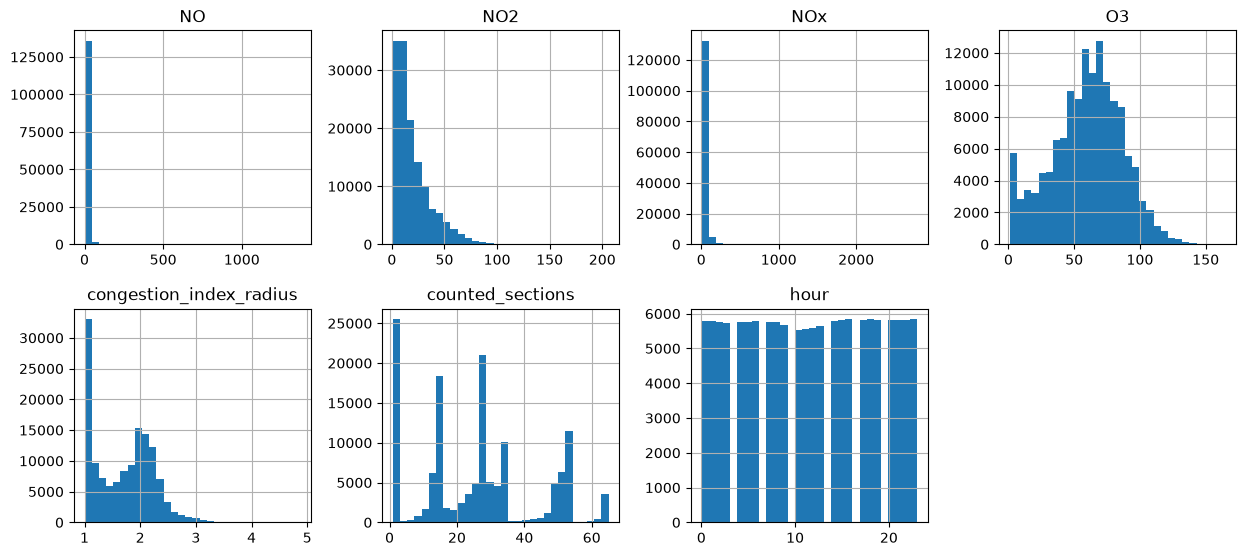

In [138]:
var_df = sensor_df.iloc[:, [0, 1, 2, 3, 4, 7, 8, 9,10, 11]] #Obtengo un dataframe con las var explicativas omitiendo las var geoespaciales
var_df.hist(bins=30, figsize=(15, 10), layout=(3, 4)) #Histograma de cada atributo

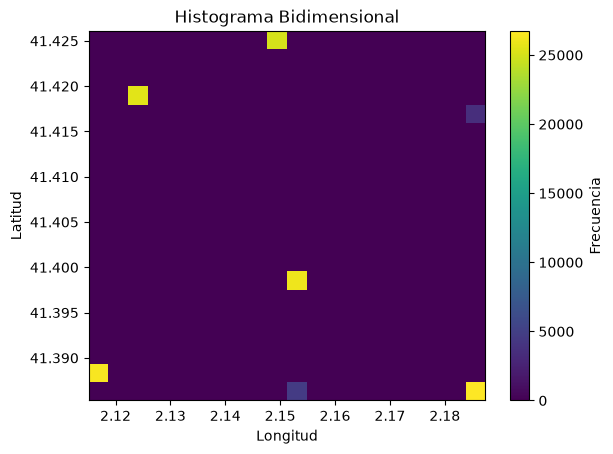

In [139]:
# Histograma bidimensional de latitud y longitud
plt.hist2d(sensor_df['longitude'], sensor_df['latitude'], bins=20, cmap='viridis')

plt.colorbar(label='Frecuencia')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Histograma Bidimensional')
plt.show()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong> comentad los resultados.
</div>

En la primera tabla podemos ver los estadísticos descriptivos pedidos e incluso más, podemos ver su rando de valores, valores max y minimos etc. Cabe destacar que podemos ver que los datos abarcan del 2023 al 2026. En los histogramas podemos ver cómo se distribuyen los atributos, la mayoría de forma asimétrica por la izquierda excepto la hora que parece ser uniforme, el O3 que parece ser normal, y la congestión que parece ser una mezcla de dos distribuciones. En el histograma bidimensional podemos entenderlo como un mapa dado que se usan los atributos, longitud y latitud. Representan cuales son las estaciones que cogen más datos y podemos ver como dos que son 'Eixample' y 'Navas' tienen menos recogida de datos por su menor frecuencia de apariciones en el dataset (las he identificado simplemente comparando ambos mapas y viendo a que puntos corresponden).

## 3.2. Análisis exploratorio de los datos

En este subapartado exploraremos gráficamente la relación de los atributos descriptivos con la variable objetivo y analizaremos las diferentes correlaciones.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> usando una librería gráfica, como por ejemplo <i>matplotlib</i>, para cada una de las variables descriptivas categóricas, mostrad la distribución de la medición de dióxido de nitrógeno (NO2) para cada uno de sus posibles valores superponiendo los histogramas de cada uno de ellos con diferentes colores y aplicando transparencia.
</div>

In [140]:
sensor_df.dtypes #Compruebo las variables que son descriptivas categóricas. 

NO                          float64
NO2                         float64
NOx                         float64
O3                          float64
station_name                 object
latitude                    float64
longitude                   float64
congestion_index_radius     float64
counted_sections              int64
station_type               category
hour                          int32
day_name                     object
is_weekend                     bool
month                        object
year                          int32
dtype: object

In [141]:
#Obtengo cuales son las var categóricas según su tipo de dato y significado
var_categoricas = sensor_df.select_dtypes(include=['object', 'bool', 'category', 'int32']).columns.tolist() 
print(f"Var. categóricas: {var_categoricas}")

Var. categóricas: ['station_name', 'station_type', 'hour', 'day_name', 'is_weekend', 'month', 'year']


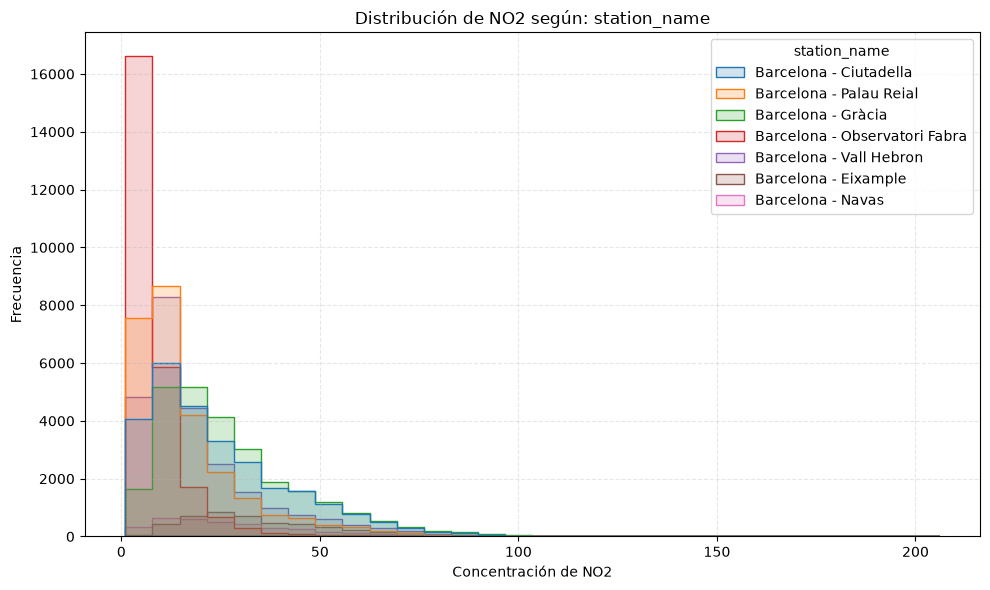

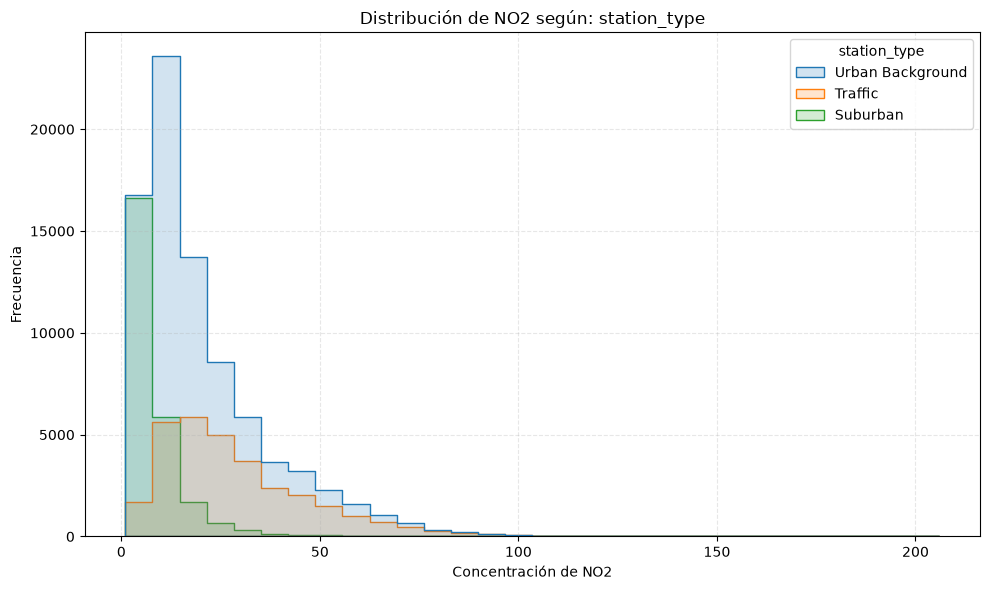

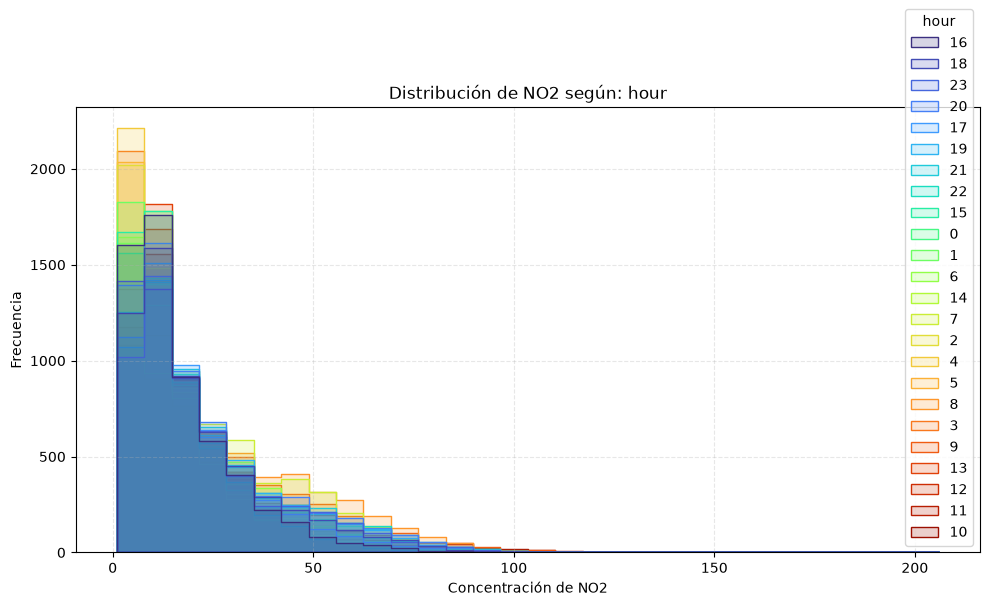

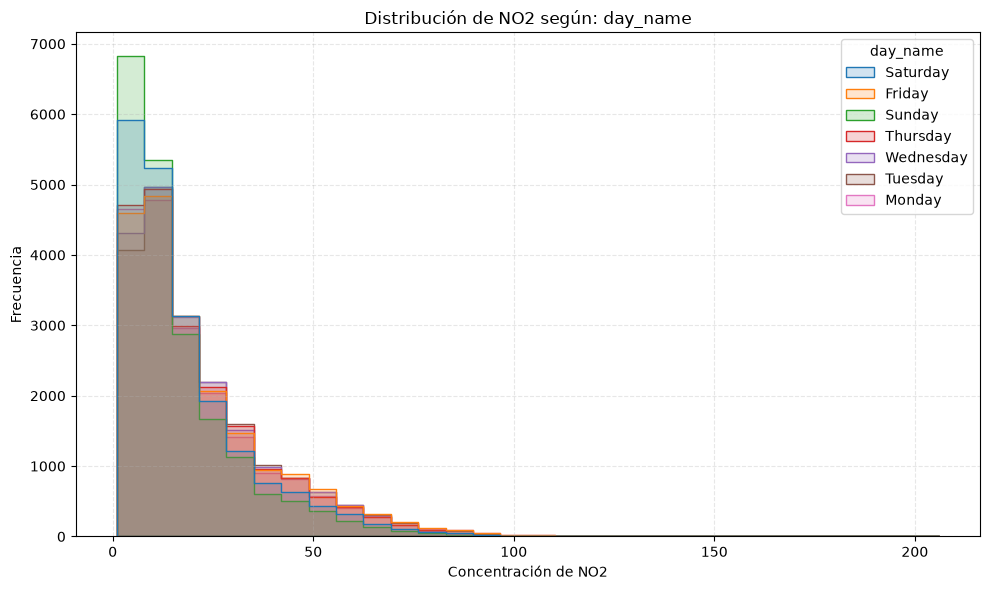

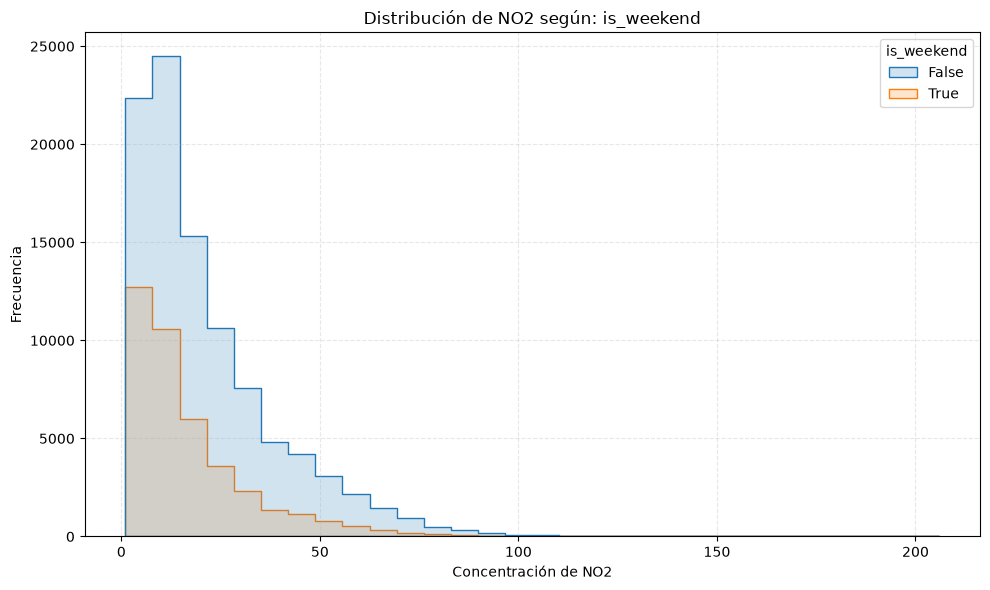

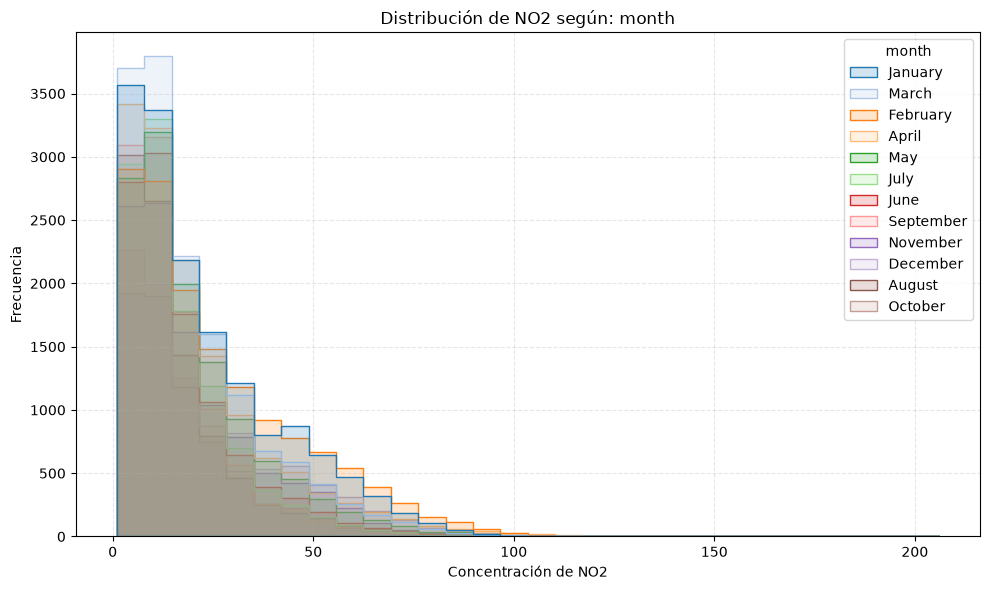

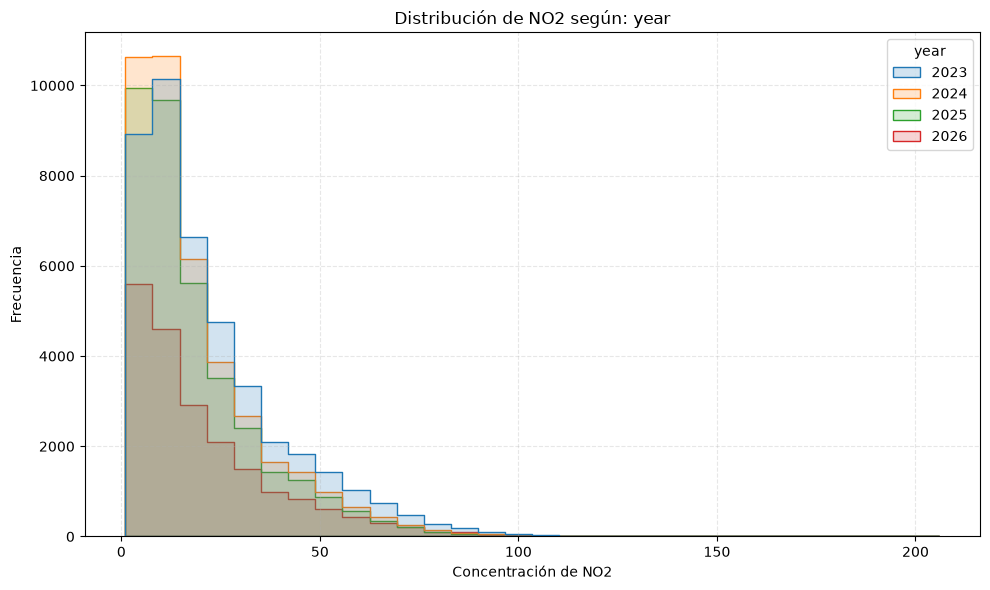

In [142]:
for feature in var_categoricas:
    plt.figure(figsize=(10, 6))
    
    # 1. Categorías ordenadas: la más frecuente primero (fondo) -> la menos frecuente al final (al frente)
    orden_frecuencia = sensor_df[feature].value_counts().index.tolist()
    num_cat = len(orden_frecuencia)
    
    # 2. Selección dinámica de la paleta para evitar repetir colores
    if num_cat <= 10:
        paleta = "tab10"
    elif num_cat <= 20:
        paleta = "tab20"
    else:
        # Genera exactamente num_cat colores únicos bien distribuidos en la paleta 'turbo'
        paleta = sns.color_palette("turbo", n_colors=num_cat)
    
    # 3. Representación del histograma superpuesto
    sns.histplot(
        data=sensor_df,
        x='NO2',
        hue=feature,
        hue_order=orden_frecuencia,
        bins=30,
        element="step",
        alpha=0.2,
        palette=paleta
    )
    
    plt.title(f'Distribución de NO2 según: {feature}')
    plt.xlabel('Concentración de NO2')
    plt.ylabel('Frecuencia')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> usando una librería gráfica, como por ejemplo <i>matplotlib</i>, para cada una de las variables descriptivas numéricas (excluyendo nombres y variables geoespaciales), mostrad la distribución de ésta respecto a la variable objetivo, poniendo, por ejemplo, en el eje X los valores de la variable descriptiva y en el eje Y los de la objetivo.
    
La finalidad de este ejercicio es la de identificar de manera visual y rápida si algunos atributos nos permiten predecir mejor que otros el valor de la variable objetivo.

Sugerencia: se recomienda utilizar <i>regplot</i>, de la biblioteca <i>seaborn</i>, ya que además de la distribución de puntos que se os pide os mostrará si hay alguna tendencia lineal positiva o negativa calculando una regresión lineal en cada caso.

Sugerencia: en caso de que el tiempo de cómputo se dispare podéis utilizar sampleado de las muestras.

In [143]:
# Variables numéricas excepto latitud y longitud
var_numericas = [
    col for col in sensor_df.select_dtypes(include=['float64', 'int64']).columns 
    if col not in ['latitude', 'longitude']
]
print(f"Var. numéricas: {var_numericas}")

Var. numéricas: ['NO', 'NO2', 'NOx', 'O3', 'congestion_index_radius', 'counted_sections']


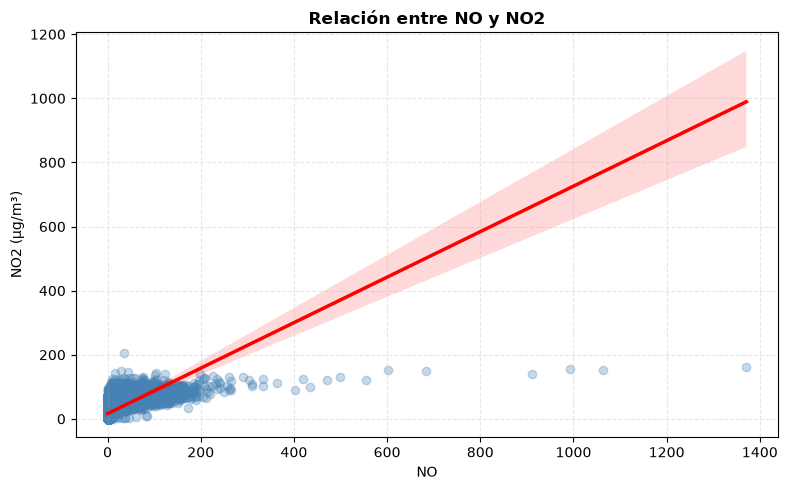

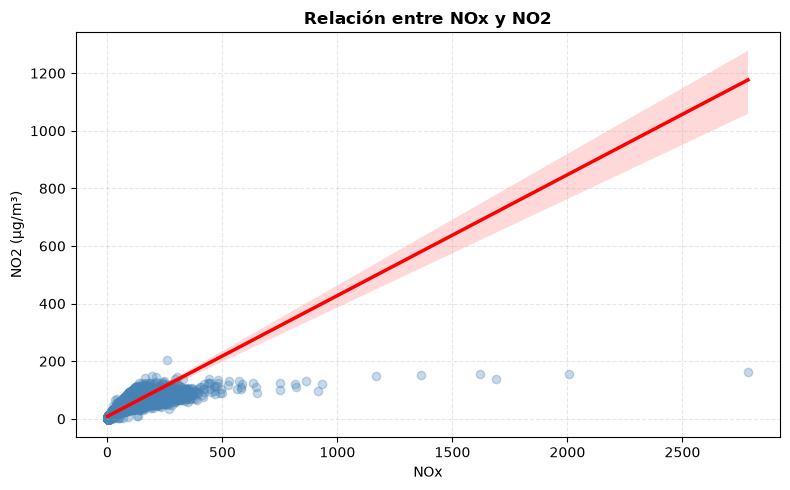

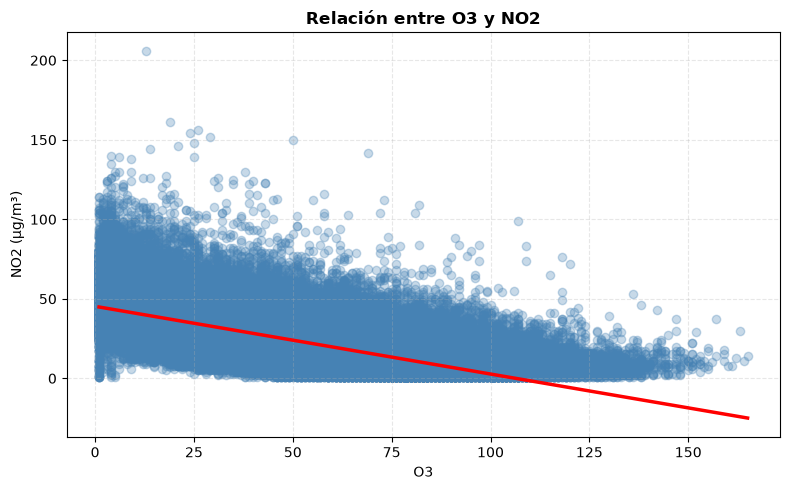

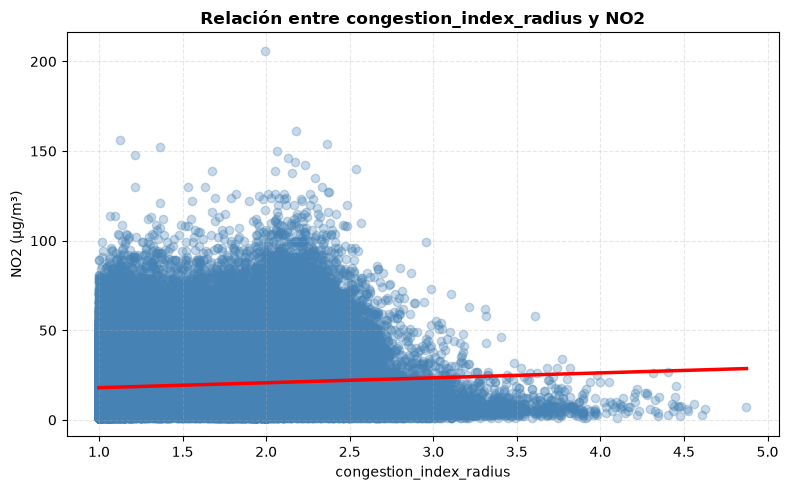

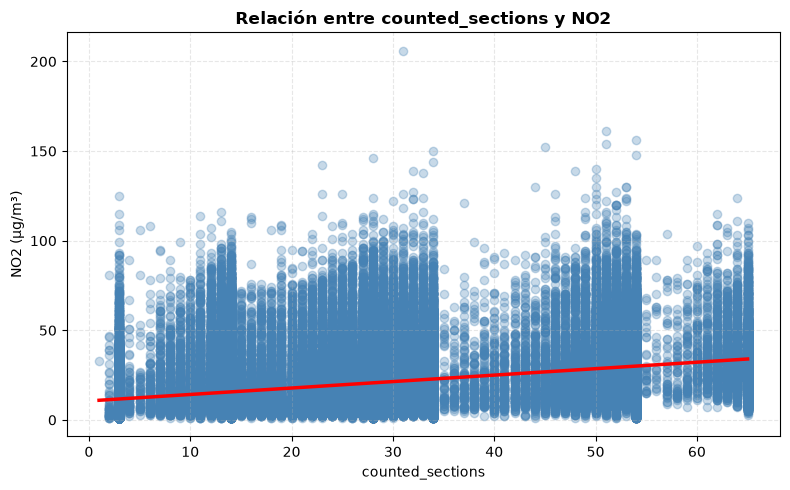

In [144]:
# Quitamos 'NO2' antes de iniciar el bucle
var_num= [col for col in var_numericas if col != 'NO2']

for feature in var_num:
    plt.figure(figsize=(8, 5))
    sns.regplot(
        data=sensor_df,
        x=feature,
        y='NO2',
        color='steelblue',                           
        line_kws={'color': 'red', 'linewidth': 2.5},
        scatter_kws={'alpha': 0.3} 
    )

    plt.title(f'Relación entre {feature} y NO2', fontsize=12, fontweight='bold')
    plt.xlabel(feature, fontsize=10)
    plt.ylabel('NO2 (µg/m³)', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong>
<br> Mirando las gráficas, ¿qué atributos parecen tener mayor influencia en el valor final de la variable objetivo? ¿Crees que con estos atributos sería suficiente para poder determinar la medición de NO2?
</div>

Los atributos **numéricos** que parecen tener mayor influencia serían: **'NO'**, **'NOx'** (veremos su problema en la siguiente pregunta) y **'O3'** (vemos como los puntos se distribuyen de forma que siguen una tendencia lineal siguiendo la recta de la regresión en cada caso). Si creo que con estos podríamos conseguir un buen ajuste para predecir **'NO2'**.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> calculad y mostrad la correlación entre las variables numéricas.
</div>

In [145]:
matriz_corr=sensor_df[var_numericas].corr(method='spearman')
print("Matriz de correlación de Spearman:")
print(matriz_corr)

Matriz de correlación de Spearman:
                               NO       NO2       NOx        O3  \
NO                       1.000000  0.683571  0.769668 -0.449124   
NO2                      0.683571  1.000000  0.984113 -0.634664   
NOx                      0.769668  0.984113  1.000000 -0.624822   
O3                      -0.449124 -0.634664 -0.624822  1.000000   
congestion_index_radius  0.283290  0.139043  0.187889  0.158717   
counted_sections         0.409352  0.445343  0.461124 -0.295608   

                         congestion_index_radius  counted_sections  
NO                                      0.283290          0.409352  
NO2                                     0.139043          0.445343  
NOx                                     0.187889          0.461124  
O3                                      0.158717         -0.295608  
congestion_index_radius                 1.000000         -0.032849  
counted_sections                       -0.032849          1.000000  


<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong> comenta los resultados asegurándote de que tu análisis responda a las siguientes preguntas: ¿hay alguna variable que tenga una correlación demasiado elevada con la variable objetivo? En caso afirmativo, ¿a qué crees que se puede deber? ¿deberíamos mantener esa variable como dato de entrada en nuestro proyecto de sensor virtual?
</div>

Si la hay, **'NOx'** con una correlación de 0.984. Esto se puede deber a que estén relacionadas ambas variables de alguna forma, ya sea porque miden algo que esta relacionado o **'NO2'** forma parte de la variable **'NOx'** para su medición. Por tanto creo que es recomendable eliminar la variable **'NOx'** por ser un posible caso de colinealidad entre ambas que hace que aporten prácticamente la misma información. En nuestro caso al ser con la variable respuesta puede causar un sobreajuste.

Podemos ver también como las variables que indiqué previamente tiene una correlación alta de casi 0.70 y -0.60 para **'NO'** y **'O3'** correspondientemente y las que no mencioné estan por debajo del 0.5. Aunque **'counted_sections'** me hace dudar por su proximidad a 0.5.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong>
<br> Una vez finalizado el EDA, se puede observar que en el mapa de la sección 2.1, con el valor original del radio a 1250 metros, la estación situada en Barcelona - Eixample es una de las que más tramos abarca en su radio. Sin embargo, en la sección 3.1, podemos ver que el histograma de la variable station_name muestra que esta estación es una de las que menos muestras tiene. ¿Podrías analizar el motivo? ¿Qué gráfico podríamos añadir al EDA para indentificar este tipo de situaciones? ¿Ves alguna situación similar con alguna otra estación?
</div>

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Barcelona - Eixample'),
  Text(1, 0, 'Barcelona - Gràcia'),
  Text(2, 0, 'Barcelona - Ciutadella'),
  Text(3, 0, 'Barcelona - Vall Hebron'),
  Text(4, 0, 'Barcelona - Palau Reial'),
  Text(5, 0, 'Barcelona - Observatori Fabra'),
  Text(6, 0, 'Barcelona - Navas')])

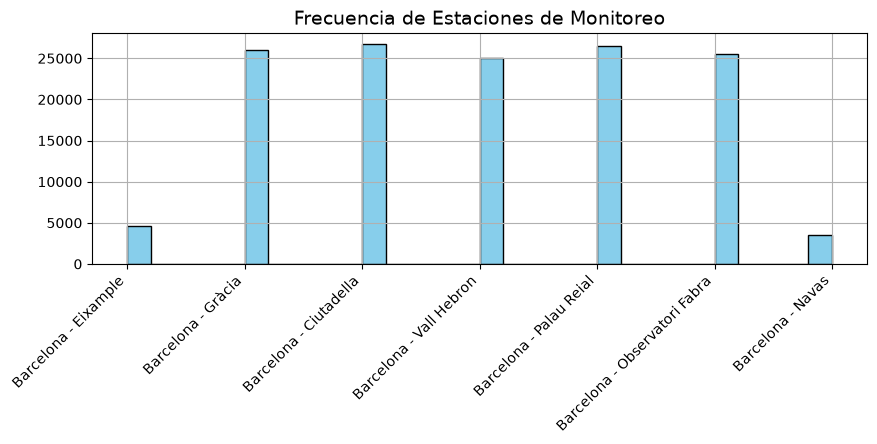

In [146]:
# Visualización de la distribución de estaciones de monitoreo en forma de histograma
sensor_df['station_name'].hist(bins=30, figsize=(10, 3), color='skyblue', edgecolor='black')
plt.title('Frecuencia de Estaciones de Monitoreo', fontsize=14)
plt.xticks(rotation=45, ha='right') # Inclinamos los nombres para que se lean bien

El **motivo** como podemos ver en el gráfico de abajo es la **falta de datos en ciertos periodos temporales**, puede que porque no se transmitiesen debido a una avería o fallo en la estación (problema de recogida o incluso que se pusiera inactiva la estación o se iniciase nueva) o por que hubo algún error y hubo que eliminar los registros de ciertas fechas (limpieza de datos). Vemos como en cambio las demás estaciones apenas dejan de transmitir.

Como vemos en el histograma que muestra cada estación frente a su frecuencia se identifican rápidamente las dos estaciones que **menos observaciones tienen 'Barcelona - Eixample' y 'Barcelona - Navas' (incluso con menos)**.

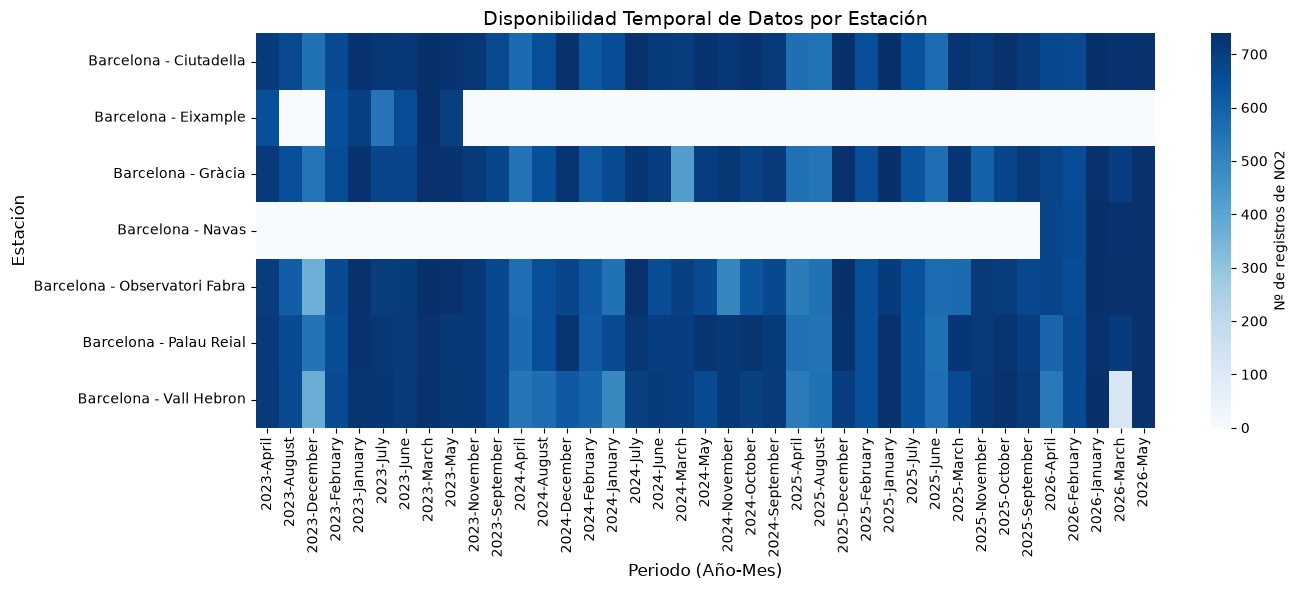

In [147]:
# Crear una variable auxiliar de periodo (Año-Mes) para agrupar
sensor_df['periodo'] = sensor_df['year'].astype(str) + '-' + sensor_df['month'].astype(str)

# Contar cuántas muestras existen por estación en cada mes
matriz_registros = sensor_df.pivot_table(
    index='station_name', 
    columns='periodo', 
    values='NO2', 
    aggfunc='count'
).fillna(0)

plt.figure(figsize=(14, 6))
sns.heatmap(matriz_registros, cmap='Blues', cbar_kws={'label': 'Nº de registros de NO2'})
plt.title('Disponibilidad Temporal de Datos por Estación', fontsize=14)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Estación', fontsize=12)
plt.tight_layout()
plt.show()

# Elimino la var auxiliar para evitar problemas luego
sensor_df.drop(columns=['periodo'], inplace=True)

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong>
<br> Hemos realizado un EDA de nuestro conjunto de datos, pero ¿sabemos qué estación es la que valores más elevados de NO2 suele tener? ¿y la que menos? ¿qué valores suelen mostrar el resto de estaciones? ¿con el EDA planteado podemos contestar a esta preguntas? En caso negativo, piensa qué gráfico añadirías para poder contestar y genéralo.
</div>

Con el EDA actual desconocemos esa información ya que en la representación de histogramas apilados por estación es dificil diferenciar bien y para ello necesitariamos otra representación/gráfico que si haga esa separación estacion/nivel NO2. Para ello realizaré un diagrama de cajas que nos permitirá responder a esas preguntas de forma adecuada.

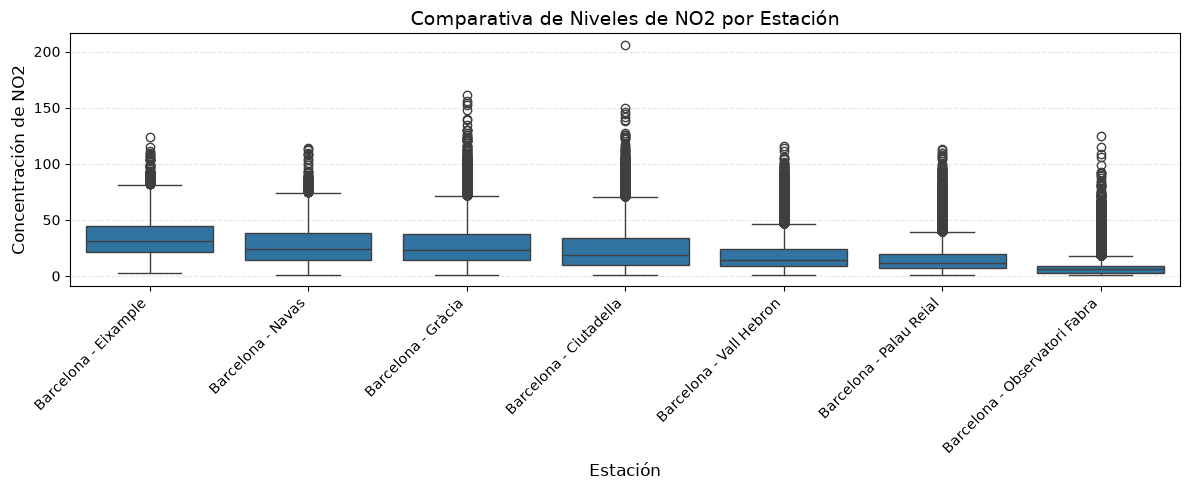

In [148]:

plt.figure(figsize=(12, 5))
# 1. Calculamos el orden de mayor a menor según la mediana de NO2 para que nos ayude a la interpretación del boxplot
orden_mediana = sensor_df.groupby('station_name')['NO2'].median().sort_values(ascending=False).index

# 2. Representamos el boxplot ordenado
sns.boxplot(
    data=sensor_df,
    x='station_name',
    y='NO2',
    order=orden_mediana, # Ordenado por mediana de NO2 
)

plt.title('Comparativa de Niveles de NO2 por Estación', fontsize=14)
plt.xlabel('Estación', fontsize=12)
plt.ylabel('Concentración de NO2', fontsize=12)
plt.xticks(rotation=45, ha='right') # Inclinamos los nombres para que se lean bien
plt.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Ahora podemos responder con que la estación que suele tener **valores más elevados de NO2 es Barcelona - Eixample** y la que **menos es Barcelona - ObservatoriFabra**. El resto de estaciones suelen mostrar valores alrededor de 25 si nos fijamos en sus respectivas medianas en el diagrama.

# 4. Preprocesado de los datos (2.5 puntos)

Una vez analizados los atributos descriptivos, es el momento de prepararlos para que nos sean útiles de cara a predecir valores.

En este apartado:
<ul>
  <li>Transformaremos los atributos descriptivos categóricos en variables numéricas para poder utilizarlas en cualquier tipo de modelo.</li>
  <li>Estandarizaremos los valores de los atributos descriptivos numéricos para que sus escalas no sean muy diferentes.</li>
  <li>Separaremos el conjunto de datos original en dos subconjuntos: entrenamiento y test.</li>
</ul>

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> transforma los atributos descriptivos categóricos en variables numéricas aplicando la técnica que mejor creas conveniente.
</div>

Ya tengo las variables categóricas identificadas de antes. Aplico a cada una su respectiva transformación:

- *station-name* la voy a retirar porque es una variable redundante ya que para identificar una estación la podemos identificar por sus coordenadas como hemos visto antes (son únicas). Para no perder la información del nombre crearé un diccionario auxiliar que asocia el nombre a las coordenadas.
- OneHotEncoder  para *station_type*
- Se aplica una transformación cíclica (seno y coseno) a *hour, day_name y month* para preservar su naturaleza periódica en un espacio continuo (1,2,...). Esto evita que un mapeo ordinal trate incorrectamente como distantes a categorías contiguas (como Domingo y Lunes, o Diciembre y Enero).
- Binarización para *is_weekend*
- Sin transformar *year* ya es numérica y no necesita modificación.

In [149]:
# 1. DICCIONARIO AUXILIAR (Coordenadas -> Nombre de la Estación)
station_lookup = (
    sensor_df[["latitude", "longitude", "station_name"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# 2. TRANSFORMACIÓN DE ATRIBUTOS (en un nuevo dataframe para no perder el original)
df_transformed = sensor_df.copy()

# A. Retirar 'station_name' (identificada de forma única por latitude y longitude)
df_transformed = df_transformed.drop(columns=["station_name"])

# B. Binarización de 'is_weekend' (bool -> int 1/0)
df_transformed["is_weekend"] = df_transformed["is_weekend"].astype(int)

# C. OneHotEncoder para 'station_type'
df_transformed = pd.get_dummies(
    df_transformed,
    columns=["station_type"],
    prefix="type",
    dtype=int,
    drop_first=True,
)

# D. Mapeo auxiliar temporal para calcular seno y coseno en day_name y month (estan por nombre de momento)
day_map = {
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6,
    "Sunday": 7,
}
month_map = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12,
}

day_num = df_transformed["day_name"].map(day_map)
month_num = df_transformed["month"].map(month_map)

# E. Transformación Cíclica (Seno / Coseno)
# - hour (período = 24)
df_transformed["hour_sin"] = np.sin(
    2 * np.pi * df_transformed["hour"] / 24.0
)
df_transformed["hour_cos"] = np.cos(
    2 * np.pi * df_transformed["hour"] / 24.0
)

# - day_name (período = 7)
df_transformed["day_sin"] = np.sin(2 * np.pi * day_num / 7.0)
df_transformed["day_cos"] = np.cos(2 * np.pi * day_num / 7.0)

# - month (período = 12)
df_transformed["month_sin"] = np.sin(2 * np.pi * month_num / 12.0)
df_transformed["month_cos"] = np.cos(2 * np.pi * month_num / 12.0)

# F. Eliminar las columnas originales temporales ya transformadas
df_transformed = df_transformed.drop(columns=["hour", "day_name", "month"])

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> En la última sección de la PEC aplicaremos dos técnicas de reducción de dimensionalidad. ¿Crees que hay alguna variable que sería conveniente eliminar de cara a ese ejercicio? Si es así, elimina un máximo de dos variables y justifica el motivo por el que se deberían eliminar. En caso de que todavía sea pronto para responder a este ejercicio, lo puede revisitar más tarde.
</div>

Creo que hay dos variables que pueden eliminarse ya:
- **NOx**, por ser un más que posible caso de colinealidad con la variable respuesta *NO2* como he comentado en el apartado de las correlaciones.
- **station_name**, como he explicado para identificar una estación ya lo podemos hacer por sus coordenadas por ende su nombre es un atributo redundante que podemos obtener a partir del diccionario que identifica la estacion a sus coordenadas. Ya ha sido eliminada en el nuevo dataset, *df_transformed* creado en el paso anterior.

In [150]:
# Elimino del dataset nuevo la var NOx 
df_transformed = df_transformed.drop(columns=["NOx"])

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> estandariza todos los atributos descriptivos numéricos, este será el nuevo conjunto de atributos descriptivos con el que trabajaremos desde ahora.
<hr>
Sugerencia: utilizad "StandardScaler" de <i>preprocessing</i>.
</div>

In [151]:
# Inicializo el StandardScaler para estandarizar los datos numéricos
scaler = StandardScaler()

# Lo aplico a los atributos numéricos descriptivos (excluyendo los que acabo de transformar, la var respuesta NO2 y la var eliminada NOx)
var_numericas.extend(["latitude", "longitude", "year"])
var_numericas.remove("NO2")
var_numericas.remove("NOx")    
df_transformed[var_numericas] = scaler.fit_transform(df_transformed[var_numericas])

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong> separa los atributos descriptivos escalados y la variable objetivo en los subconjuntos de entrenamiento y test.
<hr>
Sugerencia: para separar entre train y test podéis usar "train_test_split" de sklearn.<br>
</div>

In [152]:
X = df_transformed.drop(columns=["NO2"]) # Conjunto de atributos explicativos (X)
y = df_transformed["NO2"] # Conjunto de variable respuesta (y)

# Separo el dataset en conjunto de train y conjunto de test (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Pregunta:</strong> ¿la decisión de transformar el conjunto de datos (conversión de atributos categóricos a numéricos y estandarización) antes de realizar la separación del conjunto de datos en los subconjuntos de entrenamiento y test te parece una buena idea?
</div>

Evidentemente porque así evitamos meter sesgos en los diferentes grupos de train y test. Piensa que si al pasar de categoricos a numericos en uno de estos grupos falta una categoría la codificación ya nos fallaría. En el caso del estandarizado más de lo mismo los valores variarían dentro de cada subconjunto, es más que necesario hacerlo sobre el conjunto de datos global y luego dividirlo para evitar incluir estos sesgos.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong> en este ejercicio hemos estandarizado los valores de los atributos descriptivos para que sus escalas no sean muy diferentes. ¿Qué nos aporta estandarizar los atributos descriptivos? ¿hay alguna situación o escenario en la que sea imprescindible?
</div>

Nos aporta algo muy útil que es tener datos en una forma que diferentes atributos que en un principio tenían escalas distintas ahora sean comparables porque tenemos una media de 0 y una desviación típica de 1 después de estandarizar. Esto además nos ayuda a tener una robustez mayor ante valores atípicos por lo dicho.

**Si, la estandarización resulta imprescindible en algoritmos basados en métricas de distancia** (como *k*\-NN o *k*\-means) y en **técnicas de reducción de dimensionalidad** (como PCA), ya que previene que los atributos con unidades de medida más elevadas impongan un peso injustificado sobre los de menor escala al calcular diferencias geométricas o varianzas. También, es indispensable en **modelos que optimizan pesos** (como redes neuronales o SVM), porque facilita sustancialmente que el algoritmo aprenda los parámetros de forma estable e independiente del rango original de los datos.

# 5. Reducción de la dimensionalidad (2 puntos)

En este apartado retomaremos el análisis gráfico de distribución de la variable objetivo a lo largo de las muestras del conjunto de datos. En el tercer apartado pudimos observar si las variables descriptivas por separado eran muy prometedoras o no de cara a la predicción. Aquí vamos a intentar determinar si su combinación puede ayudarnos a determinar la medición de los niveles de NO2 de mejor manera que utilizando los atributos por separado. Con este propósito, vamos a reducir la dimensionalidad del problema a solamente dos atributos, que serán la proyección de los atributos descriptivos originales, y observaremos de qué manera se distribuyen las muestras en función de su valor objetivo.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
<ul>
    <li>Aplicad el método de reducción de la dimensionalidad Principal Component Analysis (PCA) para reducir a 2 dimensiones el dataset entero con todas las features.</li>
    <li>Con el objetivo de visualizar si es posible predecir eficientemente el valor de la variable objetivo con este método, generad un gráfico en 2D con el resultado del PCA utilizando una escala de colores que permita distinguir de forma sencilla si los valores altos o bajos se acumulan más o menos en determinadas zonas.</li>
</ul>
    
NOTA: Tened cuidado, no incluyáis la variable objetivo en la reducción de dimensionalidad. Queremos explicar la variable objetivo en función del resto de variables reducidas a dos dimensiones.

<hr>
Sugerencia: no es necesario que programéis el algoritmo de PCA, podéis usar la implementación disponible en la librería de <i>scikit-learn</i>.<br>
</div>

In [153]:
#  REDUCCIÓN DE DIMENSIONALIDAD (PCA a 2 Dimensiones)
pca = PCA(n_components=2, random_state=42)

# Entrenamos PCA con  el dataset entero con todas las features, X
X_pca = pca.fit_transform(X)

# Varianza explicada por componente principal y total acumulada
var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada CP1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada CP2: {var_exp[1]*100:.2f}%")
print(f"Varianza explicada total acumulada: {sum(var_exp)*100:.2f}%")

Varianza explicada CP1: 21.00%
Varianza explicada CP2: 13.67%
Varianza explicada total acumulada: 34.68%


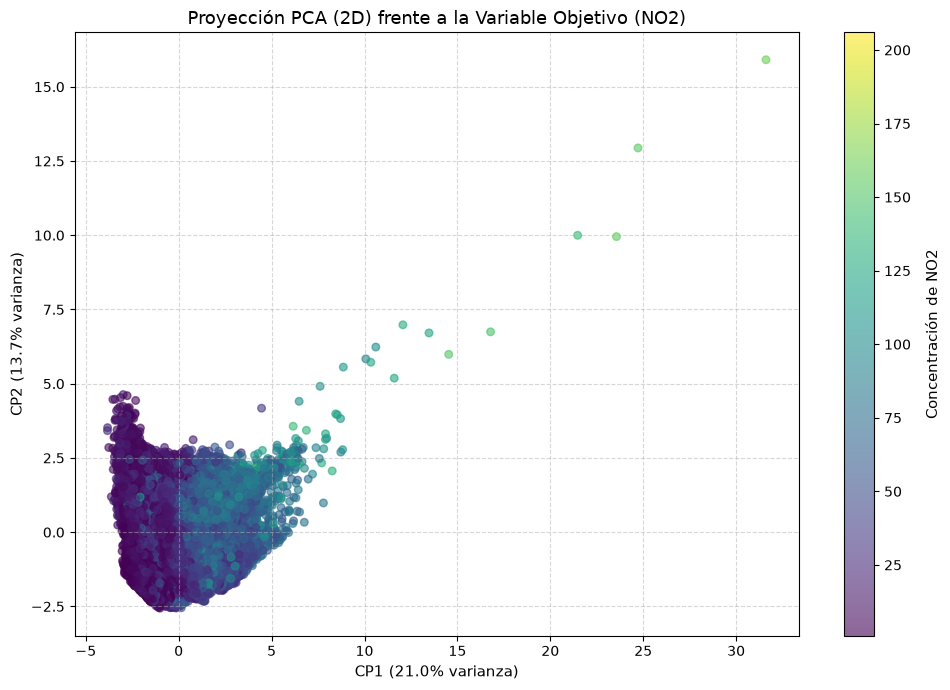

In [154]:
#  VISUALIZACIÓN EN 2D CON ESCALA DE COLORES

# DataFrame auxiliar con los 2 componentes y la variable objetivo (y)
df_pca = pd.DataFrame(
    X_pca, columns=["Componente Principal 1", "Componente Principal 2"]
)
df_pca["NO2"] = y.values

# Generamos el gráfico 2D con mapa de color continuo
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df_pca["Componente Principal 1"],
    df_pca["Componente Principal 2"],
    c=df_pca["NO2"],
    alpha=0.6,
    s=30,
)

# Barra de colores para interpretar los valores de NO2
cbar = plt.colorbar(scatter)
cbar.set_label("Concentración de NO2", fontsize=11, labelpad=10)

plt.title("Proyección PCA (2D) frente a la Variable Objetivo (NO2)", fontsize=13)
plt.xlabel(f"CP1 ({var_exp[0]*100:.1f}% varianza)", fontsize=11)
plt.ylabel(f"CP2 ({var_exp[1]*100:.1f}% varianza)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
<ul>
    <li>Repetid la reducción de dimensionalidad, pero en este caso usando TSNE.  Podéis encontrar más información acerca de este algoritmo en el siguiente enlace: <a href="https://distill.pub/2016/misread-tsne">https://distill.pub/2016/misread-tsne/</a></li>
    <li>Al igual que antes, generad un gráfico en 2D con el resultado del TSNE utilizando una escala degradada de colores para la variable objetivo ("y"), con el fin de visualizar si es posible predecir eficientemente el valor de la variable objetivo con este método.</li>
</ul>

<hr>
Sugerencia: no es necesario que programéis el algoritmo TSNE, podéis usar la implementación disponible en la librería de <i>scikit-learn</i>.<br>
Sugerencia: a parte de especificar el número de componentes, probad a usar los parámetros "learning_rate" y "perplexity".<br>
Sugerencia: en caso de que el tiempo de cómputo se dispare podéis utilizar sampleado de las muestras.
</div>

In [155]:
# MUESTREO DEL DATASET (reducir carga computacional)

# Defino un tamaño para la muestra
N_SAMPLES = 5000 

# Tomo la muestra aleatoriamente asegurando la alineación de índices entre X e y
X_sample = X.sample(n=N_SAMPLES, random_state=42)
y_sample = y.loc[X_sample.index]

In [156]:
# REDUCCIÓN DE DIMENSIONALIDAD (t-SNE a 2 Dimensiones)
tsne = TSNE(
    n_components=2,
    perplexity=50, 
    learning_rate=200, 
    random_state=42,
    n_jobs=-1,  # Usa todos los núcleos del procesador para agilizar el cálculo
)

# Transformación de las variables explicativas estandarizadas
X_tsne = tsne.fit_transform(X_sample)

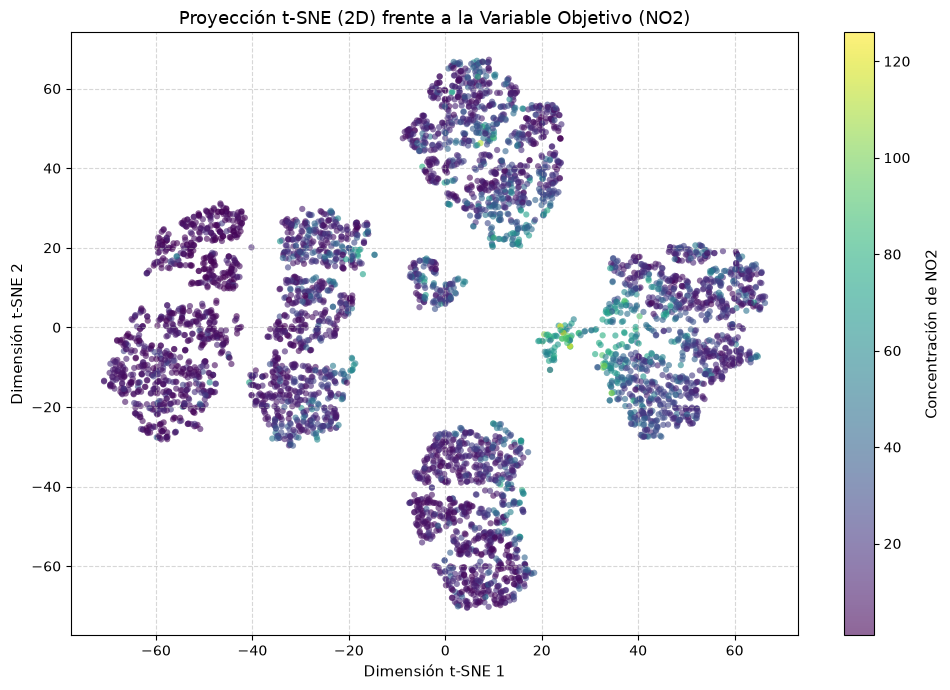

In [157]:
#  VISUALIZACIÓN EN 2D CON ESCALA DE COLORES

# DataFrame auxiliar con los 2 componentes y la variable objetivo (y)
df_tsne = pd.DataFrame(
    X_tsne, columns=["Dimensión t-SNE 1", "Dimensión t-SNE 2"]
)
df_tsne["NO2"] = y_sample.values

plt.figure(figsize=(10, 7))

# Scatter plot con degradado de colores según el nivel de NO2
scatter = plt.scatter(
    df_tsne["Dimensión t-SNE 1"],
    df_tsne["Dimensión t-SNE 2"],
    c=df_tsne["NO2"],
    cmap="viridis",
    alpha=0.6,
    edgecolors="none",
    s=20,
)

# Barra de escala de colores
cbar = plt.colorbar(scatter)
cbar.set_label("Concentración de NO2", fontsize=11, labelpad=10)

plt.title("Proyección t-SNE (2D) frente a la Variable Objetivo (NO2)", fontsize=13)
plt.xlabel("Dimensión t-SNE 1", fontsize=11)
plt.ylabel("Dimensión t-SNE 2", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Análisis:</strong> observando los dos gráficos, ¿crees que ha funcionado bien la reducción de dimensionalidad? ¿Crees que será útil para predecir el valor de la variable objetivo? ¿Cuál de los dos métodos ha funcionado mejor? ¿Por qué obtenemos resultados tan diferentes?
</div>

Creo que la reducción en dos dimensiones es bastante pobre, deberíamos incluir algunas dimensiones más para conseguir una mejor separación de los valores de *NO2*, por ende en general la separación por sólo dos dimensiones no es muy útil. Es fácil de comprobar esto cuando por ejemplo en PCA tenemos una variabilidad total acumulada de menos del 50% (~35%), lo cual significa que con dos componentes principales no somos capaces de capturar más del 35% de la variabilidad de los datos. 

En el caso del t-SNE parece que la separación por clusters es capaz de separar los valores altos de NO2 de mejor manera que en el PCA. Aún así podemos ver como en más de uno quedan valores extremos casi superpuestos. Esta obtención de resultados tan distintos se debe a la forma en la que funcioan estos métodos, PCA de forma linear (vemos como la primera componente va de valores bajos a altos de NO2) y t-SNE de froma no linear agrupando por clusters en función de la similitud entre los puntos.

<div style="background-color: #EDF7FF; border-color: #7C9DBF; border-left: 5px solid #7C9DBF; padding: 0.5em;">
<strong>Pregunta:</strong> ¿qué opinas de TSNE como opción para reducir la dimensionalidad? ¿Qué te parece que sólo tenga el método "fit_transform" pero no tenga "transform"? ¿Conoces alguna otra opción que, con unas prestaciones similares, evite los problemas que tiene TSNE?
</div>

Parece ser una buena opción para reducir la dimensionalidad en espacios de datos no lineales, precisamente porque es una técnica no lineal de aprendizaje en variedades (*manifold learning*). Sin embargo, el hecho de que solo cuente con el método **fit_transform** y carezca de *transform* constituye una limitación importante para escenarios predictivos, ya que **no permite proyectar nuevos datos de prueba o producción** sin tener que reentrenar el algoritmo sobre todo el conjunto combinado, con el **riesgo de fugas de información (data leakage)** y un altísimo coste computacional. 

Como alternativa más robusta, UMAP (Uniform Manifold Approximation and Projection) ofrece un rendimiento y una preservación de estructuras no lineales (tanto locales como globales) similares o superiores a t-SNE, pero superando sus principales desventajas al ser drásticamente más rápido, escalar mejor con grandes volúmenes de datos y disponer del método .transform() para proyectar nuevas muestras de forma consistente.